# **MATRIX COMPLETION VIA FRANK-WOLFE OPTIMIZATION**

This notebook implements the Frank-Wolfe (FW) algorithm to solve the Matrix Completion problem. The objective is to reconstruct a target matrix $X \in \mathbb{R}^{n_1 \times n_2}$ from a sparse set of observed entries $R_{ij}$ at indices $\Omega$.

To encourage a low-rank reconstruction, we use the nuclear norm constraint ($\|X\|_* \le \tau$) as a convex proxy for the matrix rank. The optimization problem is formulated as:

$$ \min_{X \in \mathbb{R}^{n_1 \times n_2}} f(X) := \frac{1}{2} \sum_{(i,j) \in \Omega} (X_{ij} - R_{ij})^2 \quad \text{s.t.} \quad \|X\|_* \le \tau $$

### **1. Gradient and Linear Minimization Oracle (LMO)**
The objective function's gradient is highly sparse, evaluating only at the observed indices: $\nabla f(X_k) = (X_k - R)_\Omega$.
    
The feasible set is the nuclear norm ball. The LMO finds the steepest descent direction within this set by computing a rank-one matrix:
$$ S_k = \tau u_1 v_1^T $$
where $u_1$ and $v_1$ are the top left and right singular vectors of $-\nabla f(X_k)$.

### **2. Exact Line Search**
To maximize the progress at each iteration, the step size $\gamma_k$ is computed using an Exact Line Search. This finds the optimal scaling factor along the descent direction $d_k$:
$$ \gamma_k \in \arg\min_{\gamma \in [0, 1]} f(X_k + \gamma d_k) $$

## **Standard Frank-Wolfe for Matrix Completion**

The Standard Frank-Wolfe algorithm iteratively solves the nuclear-norm constrained matrix completion problem by adding one rank-1 feature at a time.

* **1. Gradient Calculation:** The algorithm computes the gradient of the squared error loss, which is the matrix of residuals evaluated strictly at the observed user-item coordinates: $\nabla f(X_k) = P_\Omega(X_k - R)$.
* **2. Linear Minimization Oracle (LMO):** It determines the steepest descent direction by minimizing the linear approximation of the objective over the nuclear norm ball. Utilizing a 1-SVD, it extracts the top left ($u$) and right ($v$) singular vectors of the negative gradient to construct the optimal rank-1 update atom: $s_k = \tau u v^T$.
* **3. Duality Gap (Convergence Check):** It computes the Frank-Wolfe duality gap: $g_k = \langle -\nabla f(X_k), s_k - X_k \rangle$. This gap acts as a strict upper bound on the primal suboptimality $f(X_k) - f(X^*)$; the algorithm halts if $g_k$ drops below the predefined tolerance.
* **4. Exact Line Search:** It establishes the optimal scalar step size $\gamma \in [0, 1]$ to move toward the new atom $s_k$. Because the objective is a purely quadratic function, $\gamma$ is computed algebraically in closed form, completely avoiding iterative approximations: $\gamma_k = \frac{\langle -\nabla f(X_k), s_k - X_k \rangle}{\Vert{}P_\Omega(s_k - X_k)\Vert{}_F^2}$.
* **5. State and Active Set Update:** The new prediction matrix is formed through a convex combination: $X_{k+1} = (1 - \gamma_k) X_k + \gamma_k s_k$. The weights of all historical atoms within the active set are uniformly decayed by multiplying them by $(1 - \gamma_k)$, and the new atom $s_k$ is appended with weight $\gamma_k$.



In [1]:
def frank_wolfe_standard(users, items, ratings, n_users, n_items, tau, max_iter=50, tol = 1e-8, gap_tol=1e-8, v_users=None, v_items=None, v_ratings=None):
    # 1) initialization
    predictions = np.zeros(len(ratings))

    active_set = [{"u": None, "v": None, "alpha": 1.0, "zero": True}]

    # i) Metrics
    objective_history = []
    train_rmse_history = []
    val_rmse_history = []
    fw_gap_history = []
    active_set_size_history = []
    time_history = []
    start_time = time.time()

    # ii) Initial loss
    t_users = users
    t_items = items
    t_ratings = ratings

    # We compute del loss through the residuals
    residuals = predictions - t_ratings
    initial_train_loss = 0.5 * np.sum(residuals ** 2)
    objective_history.append(initial_train_loss)
    initial_train_rmse = np.sqrt(np.mean(residuals ** 2))
    train_rmse_history.append(initial_train_rmse)


    # iii) Baseline validation
    if v_users is not None and v_items is not None and v_ratings is not None:
        val_preds = np.zeros(len(v_ratings))
        initial_val_rmse = np.sqrt(np.mean((val_preds - v_ratings) ** 2))
        val_rmse_history.append(initial_val_rmse)
        print(f"Initial RMSE: {initial_val_rmse:.4f}")

    # 2) Iteration
    for k in range(max_iter):

        # i) Gradient
        residuals = predictions - t_ratings
        grad = sp.csr_matrix(
            (residuals, (t_users, t_items)),
            shape=(n_users, n_items)
        )

        # ii) LMO oracle
        u_new, _, vt_new = svds(grad, k=1, which="LM", random_state=42)
        toward_u = -u_new[:, 0]
        toward_v = vt_new[0, :]

        # observed atom extractions
        toward_obs = tau * (toward_u[t_users] * toward_v[t_items])

        # 3 Duality Gap
        duality_gap = np.sum(residuals * (predictions - toward_obs))
        fw_gap_history.append(max(duality_gap, 1e-10))

        # ii) Convergence Checking:
        if duality_gap < tol:
            print(f"Converged at iteration {k} (Gap = {duality_gap:.2e}).")
            break

        # 4 Step size with Line Search
        # 1) Direction updating
        dir = toward_obs - predictions
        d = np.sum(dir ** 2)

        # ii) gamma*
        if d > 1e-12:
            gamma = duality_gap / d
        else:
            gamma = 0.0

        # gamma must be [0, 1]
        gamma = np.clip(gamma, 0.0, 1.0)

        # 5 Updating phase
        predictions = (1.0 - gamma) * predictions + gamma * toward_obs

        # i) Atom updating
        for atom in active_set:
            atom["alpha"] *= (1.0 - gamma)

        active_set.append({
            "u": toward_u,
            "v": toward_v,
            "alpha": gamma,
            "zero": False
        })

        # ii) Pruning
        active_set = [atom for atom in active_set if atom["alpha"] > tol]
        active_set_size_history.append(len(active_set))

        # ii) Training loss storage
        train_loss = 0.5 * np.sum((predictions - t_ratings) ** 2)
        objective_history.append(train_loss)
        train_rmse_history.append(np.sqrt(np.mean((predictions - t_ratings) ** 2)))

        msg = f"Iter {k+1:02d}/{max_iter} | Train Loss: {train_loss:.2f} | Gap: {duality_gap:.2f}"

        if v_users is not None and v_items is not None and v_ratings is not None:
            # validation loss
            val_preds = np.zeros(len(v_ratings))
            for atom in active_set:
                if not atom["zero"]:
                    val_preds += atom["alpha"] * tau * (atom["u"][v_users] * atom["v"][v_items])

            val_rmse = np.sqrt(np.mean((val_preds - v_ratings) ** 2))
            val_rmse_history.append(val_rmse)
            msg += f" | Val RMSE: {val_rmse:.4f}"

        current_time = time.time() - start_time
        time_history.append(current_time)


        msg += f" | Time: {current_time:.2f}s"
        print(msg)

    # Return
    return active_set, objective_history, fw_gap_history, train_rmse_history, val_rmse_history, active_set_size_history, time_history

## **Away-Step Frank-Wolfe for Matrix Completion**

The Away-Step Frank-Wolfe (AFW) algorithm extends the standard method to mitigate the sublinear "zig-zagging" phenomenon on domain boundaries by explicitly allowing the removal of weight from suboptimal historical atoms. 

* **1. Gradient Calculation:** Identical to the standard method, it computes the sparse residual matrix evaluated at the observed user-item indices: $\nabla f(X_k) = P_\Omega(X_k - R)$.
* **2. Linear Minimization Oracle (Toward Step):** It uses a 1-SVD to extract the leading singular vectors of the negative gradient, constructing the standard FW rank-1 atom $s_k = \tau u v^T$.
* **3. Away Atom Selection:** It evaluates the historical atoms currently defining the matrix $X_k$ to identify the "worst" atom $v_k$. This is achieved by finding the active atom that maximizes the inner product with the gradient, $\arg\max_{v \in \mathcal{S}^{(k)}} \langle \nabla f(X_k), v \rangle$.
* **4. Direction Selection:** The algorithm evaluates two competing descent directions. It calculates the FW duality gap $g_k^{FW} = \langle -\nabla f(X_k), s_k - X_k \rangle$ and the away gap $g_k^A = \langle -\nabla f(X_k), X_k - v_k \rangle$. It then explicitly selects the direction that guarantees the steepest descent: either $d_k = s_k - X_k$ (if $g_k^{FW} \ge g_k^A$) or $d_k = X_k - v_k$ (if $g_k^A > g_k^{FW}$).
* **5. Exact Line Search & Bounded Step Size:** It computes the exact scalar step size $\gamma$ algebraically for the quadratic squared error objective. Crucially, if an away direction is chosen, the step size is mathematically constrained to $\gamma_{max} = \frac{\alpha_{v_k}}{1 - \alpha_{v_k}}$ (where $\alpha_{v_k}$ is the current weight of $v_k$). This ensures the new matrix remains strictly inside the feasible nuclear norm ball.
* **6. State Update and Drop Steps:** The new matrix is updated via $X_{k+1} = X_k + \gamma d_k$. If an away step is executed and reaches the constraint bound ($\gamma = \gamma_{max}$), a "drop step" occurs: the weight of $v_k$ becomes exactly zero, and it is permanently pruned from the active set to maintain extreme sparsity.

In [2]:
def away_step_frank_wolfe(users, items, ratings, n_users, n_items, tau=1000, max_iter=20,
                          gap_tol=1e-3, numerical_tol=1e-12, weight_tol=1e-12, v_users=None, v_items=None, v_ratings=None):
    # Initialize active set
    predictions = np.zeros(len(ratings))
    active_set = [{"u": None, "v": None, "alpha": 1.0, "zero": True}]

    objective_history = []
    train_rmse_history = []
    val_rmse_history = []
    fw_gap_history = []
    active_set_size_history = []
    time_history = []
    gap0 = None
    start_time = time.time()

    for iteration in range(max_iter + 1):
        # 1. Compute the gradient
        residuals = predictions - ratings
        objective = 0.5 * np.sum(residuals ** 2)
        gradient = sp.csr_matrix((residuals, (users, items)), shape=(n_users, n_items))

        # 2. LMO
        u_new, _, vt_new = svds(gradient, k=1, which="LM", random_state=42)
        toward_u = -u_new[:, 0]
        toward_v = vt_new[0, :]
        toward_obs = tau * (toward_u[users] * toward_v[items])

        # 3. Evaluate the new atom
        objective_history.append(objective)
        train_rmse_history.append(np.sqrt(np.mean(residuals ** 2)))

        # 4. Compute the gap
        fw_gap = np.dot(residuals, predictions - toward_obs)
        fw_gap_history.append(fw_gap)

        # Store gap at first iteration
        if gap0 is None:
            gap0 = max(fw_gap, 1e-12)
        relative_gap = fw_gap / gap0

        # 5. Validation RMSE
        if v_users is not None and v_items is not None and v_ratings is not None:
            val_preds = np.zeros(len(v_ratings))
            for atom in active_set:
                if not atom["zero"]:
                    val_preds += atom["alpha"] * tau * (atom["u"][v_users] * atom["v"][v_items])
            val_rmse_history.append(np.sqrt(np.mean((val_preds - v_ratings) ** 2)))

        n_rank1_atoms = sum(not atom["zero"] for atom in active_set)
        active_set_size_history.append(n_rank1_atoms)

        # 6. Check convergence
        if relative_gap <= gap_tol:
            print(f"Converged at iteration {iteration} (Relative gap = {relative_gap:.3e}).")
            break
        if iteration == max_iter:
            print(f"Stopped at iteration {iteration}: max_iter reached (Relative FW gap = {relative_gap:.3e}).")
            break

        # 7. Away-Step iteration
        away_scores = []
        for atom in active_set:
            if atom["zero"]:
                score = -np.inf
            else:
                score = tau * np.sum(residuals * atom["u"][users] * atom["v"][items])
            away_scores.append(score)

        away_index = np.argmax(away_scores)
        away_atom = active_set[away_index]

        # 8. Evaluate the away atom
        if away_atom["zero"] or len([a for a in active_set if not a["zero"]]) == 0:
            away_obs = np.zeros(len(ratings))
            away_gap = -np.inf
        else:
            away_obs = tau * (away_atom["u"][users] * away_atom["v"][items])
            away_gap = np.dot(residuals, away_obs - predictions)

        # 9. Direction selection
        if fw_gap >= away_gap:
            is_away_step = False
            direction_obs = toward_obs - predictions
            gamma_max = 1.0
        else:
            is_away_step = True
            direction_obs = predictions - away_obs
            alpha_v = away_atom["alpha"]
            if alpha_v >= 1.0 - numerical_tol: # bounded step size
                gamma_max = np.inf
            else:
                gamma_max = alpha_v / (1.0 - alpha_v)

        # 10. Exact Line Search
        denominator = np.dot(direction_obs, direction_obs)
        if denominator <= numerical_tol:
            break

        gamma = -np.dot(residuals, direction_obs) / denominator
        gamma = np.clip(gamma, 0.0, gamma_max)

        if gamma <= numerical_tol:
            break

        predictions = predictions + gamma * direction_obs

        # 11. Weight updates
        if is_away_step:
            for i, atom in enumerate(active_set):
                if i == away_index:
                    atom["alpha"] = (1.0 + gamma) * atom["alpha"] - gamma
                else:
                    atom["alpha"] = (1.0 + gamma) * atom["alpha"]
        else:
            for atom in active_set:
                atom["alpha"] *= (1.0 - gamma)

            # Adding new atom to the active set
            active_set.append({
                "u": toward_u,
                "v": toward_v,
                "alpha": gamma,
                "zero": False
            })

        # Pruning step
        total_alpha = sum(atom["alpha"] for atom in active_set)
        for atom in active_set:
            atom["alpha"] /= total_alpha
            if abs(atom["alpha"]) <= weight_tol:
                atom["alpha"] = 0.0

        active_set = [atom for atom in active_set if atom["alpha"] > 0.0]

        current_time = time.time() - start_time
        time_history.append(current_time)

        msg = f"Iter {iteration+1:02d}/{max_iter} | Train Loss: {objective:.2f} | Gap: {fw_gap:.2f}"
        if v_users is not None and v_items is not None and v_ratings is not None:
            msg += f" | Val RMSE: {val_rmse_history[-1]:.4f}"
        step_type = "Away" if is_away_step else "FW"
        msg += f" | Time: {current_time:.2f}s | Step: {step_type}"
        print(msg)

    return active_set, objective_history, fw_gap_history, train_rmse_history, val_rmse_history, active_set_size_history, time_history

## **Pairwise Frank-Wolfe for Matrix Completion**

The Pairwise Frank-Wolfe (PFW) algorithm simplifies the Away-Step logic by combining the "toward" and "away" movements into a single, unified swap operation, shifting mass directly from a bad historical atom to a new promising one.

* **1. Gradient Calculation:** As with the other variants, it calculates the highly sparse matrix of residuals restricted to the observed user-item dataset coordinates: $\nabla f(X_k) = P_\Omega(X_k - R)$.
* **2. Linear Minimization Oracle (Best Atom):** It executes a 1-SVD on the negative gradient to extract the leading singular vectors, generating the optimal "toward" rank-1 atom $s_k = \tau u v^T$.
* **3. Away Atom Selection (Worst Atom):** It scans the active set $\mathcal{S}^{(k)}$ to find the historical atom $v_k$ that is currently performing the worst. This is mathematically identified as the atom maximizing the inner product with the gradient: $v_k = \arg\max_{v \in \mathcal{S}^{(k)}} \langle \nabla f(X_k), v \rangle$.
* **4. Pairwise Direction:** Instead of choosing between moving toward $s_k$ or away from $v_k$, it creates a combined direction vector $d_k = s_k - v_k$. This specific direction allows the algorithm to directly transfer weight from the bad atom to the good atom.
* **5. Exact Line Search & Bounded Step Size:** The scalar step size $\gamma$ is computed exactly by finding the minimum of the quadratic objective along the direction $d_k$. To maintain convex combinations and prevent negative weights, the maximum allowable step size is strictly bounded by the current weight of the worst atom: $\gamma_{max} = \alpha_{v_k}$.
* **6. State Update and Drop Steps:** The matrix is updated via $X_{k+1} = X_k + \gamma d_k$. The weight $\gamma$ is added to $s_k$ and subtracted from $v_k$. If the step size hits the upper bound ($\gamma = \gamma_{max}$), the weight of $v_k$ drops to exactly zero. This triggers either a drop step (reducing the active set cardinality) or a swap step (if $s_k$ replaces $v_k$, leaving cardinality unchanged).

In [3]:
def pairwise_frank_wolfe(users, items, ratings, n_users, n_items, tau=1000, max_iter=20,
                         gap_tol=1e-3, numerical_tol=1e-12, weight_tol=1e-12, duplicate_tol=1e-8,
                         v_users=None, v_items=None, v_ratings=None):
    # Initialization active set
    predictions = np.zeros(len(ratings))
    active_set = [{"u": None, "v": None, "alpha": 1.0, "zero": True}]

    objective_history = []
    train_rmse_history = []
    val_rmse_history = []
    fw_gap_history = []
    active_set_size_history = []
    time_history = []
    gap0 = None
    start_time = time.time()

    # Main loop
    for iteration in range(max_iter + 1):

        # FIRST STEP: evaluating current error
        residuals = predictions - ratings
        objective = 0.5 * np.sum(residuals ** 2)

        # Computing gradient function
        gradient = sp.csr_matrix(
            (residuals, (users, items)),
            shape=(n_users, n_items)
        )

        # SECOND STEP: find the "best" atom (LMO)
        u_new, _, vt_new = svds(gradient, k=1, which="LM", random_state=42)
        toward_u = -u_new[:, 0]
        toward_v = vt_new[0, :]
        toward_obs = tau * (toward_u[users] * toward_v[items])

        # Duality gap calculation
        fw_gap = np.dot(residuals, predictions - toward_obs)
        fw_gap_history.append(fw_gap)

        # Store gap at first iteration
        if gap0 is None:
            gap0 = max(fw_gap, 1e-12)
        relative_gap = fw_gap / gap0

        # Metrics
        objective_history.append(objective)
        train_rmse_history.append(np.sqrt(np.mean(residuals ** 2)))

        if v_users is not None and v_items is not None and v_ratings is not None:
            val_preds = np.zeros(len(v_ratings))
            for atom in active_set:
                if not atom["zero"]:
                    val_preds += atom["alpha"] * tau * (atom["u"][v_users] * atom["v"][v_items])
            val_rmse_history.append(np.sqrt(np.mean((val_preds - v_ratings) ** 2)))

        n_rank1_atoms = sum(not atom["zero"] for atom in active_set)
        active_set_size_history.append(n_rank1_atoms)

        if relative_gap <= gap_tol:
            print(f"Converged at iteration {iteration} "
                  f"(Relative gap = {relative_gap:.3e}).")
            break

        if iteration == max_iter:
            break
        # THIRD STEP: find the "worst" atom
        away_scores = []
        for atom in active_set:
            if atom["zero"]:
                score = 0.0
            else:
                score = tau * np.sum(residuals * atom["u"][users] * atom["v"][items])
            away_scores.append(score)

        away_index = np.argmax(away_scores)
        away_atom = active_set[away_index]

        if away_atom["zero"]:
            away_obs = np.zeros(len(ratings))
        else:
            away_obs = tau * (away_atom["u"][users] * away_atom["v"][items])

        # FOURTH STEP: pairwise direction
        direction_obs = toward_obs - away_obs
        denominator = np.dot(direction_obs, direction_obs)

        if denominator <= numerical_tol:
            print(f"Stopped at iteration {iteration} (Zero direction denominator).")
            break

        # FIFTH STEP: line search and maximum step size (weight gamma)
        gamma = -np.dot(residuals, direction_obs) / denominator
        gamma_max = away_atom["alpha"]
        gamma = np.clip(gamma, 0.0, gamma_max)

        if gamma <= numerical_tol:
            print(f"Stopped at iteration {iteration} (Step size near zero).")
            break

        # LAST STEP: update and prune (drop step)
        if gamma_max - gamma <= weight_tol:
            gamma = gamma_max

        predictions = predictions + gamma * direction_obs
        active_set[away_index]["alpha"] -= gamma

        duplicate_found = False
        for atom in active_set:
            if not atom["zero"]:
                similarity = (np.dot(atom["u"], toward_u) * np.dot(atom["v"], toward_v))
                if similarity > 1.0 - duplicate_tol:
                    atom["alpha"] += gamma
                    duplicate_found = True
                    break

        if not duplicate_found:
            active_set.append({
                "u": toward_u,
                "v": toward_v,
                "alpha": gamma,
                "zero": False
            })

        # Coefficients check
        total_alpha = sum(atom["alpha"] for atom in active_set)
        assert np.isclose(total_alpha, 1.0, atol=1e-10, rtol = 0.0)
        assert all(atom["alpha"] >= -weight_tol for atom in active_set)

        # Numerical cleanup + pruning
        for atom in active_set:
            if abs(atom["alpha"]) <= weight_tol:
                atom["alpha"] = 0.0

        active_set = [atom for atom in active_set if atom["alpha"] > 0.0]
        n_rank1_atoms_current = sum(not atom["zero"] for atom in active_set)
        current_time = time.time() - start_time
        time_history.append(current_time)

        msg = f"Iter {iteration+1:02d}/{max_iter} | Train Loss: {objective:.2f} | Gap: {fw_gap:.2f}"

        if v_users is not None and v_items is not None and v_ratings is not None:
            val_rmse_current = val_rmse_history[-1]
            msg += f" | Val RMSE: {val_rmse_current:.4f}"

        msg += f" | Time: {current_time:.2f}s"
        print(msg)


    return active_set, objective_history, fw_gap_history, train_rmse_history, val_rmse_history, active_set_size_history, time_history

## **Loading, Cleaning and Handle data**

In [4]:
%pip install datasets
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display
import time
import scipy.sparse as sp
from scipy.sparse.linalg import svds
from datasets import load_dataset
from sklearn.model_selection import train_test_split

def fetch_clean_split_data(hf_name, user_col, item_col, rating_col, min_ratings=10):
    """
    Through this function, we download and clean the real case datasets
    """
    dataset_name = hf_name.split('/')[-1]
    print(f"Downloading & Processing: {hf_name} ...")

    # 1. Download dataset
    dataset = load_dataset(hf_name, split='train')
    df = dataset.to_pandas()

    # 2. Extract & rename columns
    df = df[[user_col, item_col, rating_col]].copy()
    df.columns = ['user_id', 'item_id', 'rating']
    df = df.dropna()

    # 3. Handle the cold start problem
    tot_user = df['user_id'].value_counts()
    relevant_users = tot_user[tot_user >= min_ratings].index
    df = df[df['user_id'].isin(relevant_users)].copy()

    # 4. Map IDs to 0-indexed integers (crucial for matrix coordinates)
    df['user_idx'], _ = pd.factorize(df['user_id'])
    df['item_idx'], _ = pd.factorize(df['item_id'])

    n_users = df['user_idx'].max() + 1
    n_items = df['item_idx'].max() + 1

    # 5. Train - Validation - Test split (80/10/10)
    train_df, valtest_df = train_test_split(
        df, test_size=0.20, random_state=42, stratify=df["user_idx"]
    )
    val_df, test_df = train_test_split(
        valtest_df, test_size=0.50, random_state=42, stratify=valtest_df["user_idx"]
    )

    # Reset indices for cleanliness
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    print(f"Users: {n_users} | Items: {n_items} | Ratings: {len(df)}\n")
    print(f"DATASET: {dataset_name}")
    print("TRAIN SET")
    print(train_df.head(), "\n")

    print("VALIDATION SET")
    print(val_df.head(), "\n")

    print("TEST SET")
    print(test_df.head(), "\n")
    print("-" * 70, "\n")
    return train_df, val_df, test_df, n_users, n_items


# 1) MovieLens 100k
ml_train, ml_val, ml_test, ml_n_users, ml_n_items = fetch_clean_split_data(
    hf_name="DukeNLPGroup/movielens-100k",
    user_col="user_id", item_col="movie_id", rating_col="user_rating"
)

# 2) Amazon Video Games
amz_train, amz_val, amz_test, amz_n_users, amz_n_items = fetch_clean_split_data(
    hf_name="LoganKells/amazon_product_reviews_video_games",
    user_col="reviewerID", item_col="asin", rating_col="overall"
)

# 3) MyAnimeList Recommendations
anime_train, anime_val, anime_test, anime_n_users, anime_n_items = fetch_clean_split_data(
    hf_name="krishnaveni76/Anime_UserRatings",
    user_col="user_id", item_col="anime_id", rating_col="average_rating"
)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\carlo\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Users: 943 | Items: 1682 | Ratings: 100000

DATASET: movielens-100k
TRAIN SET
  user_id  item_id  rating  user_idx  item_idx
0  b'741'   b'399'     2.0       357       781
1  b'552'     b'1'     3.0       866       399
2  b'245'   b'717'     4.0       762       294
3  b'435'  b'1034'     2.0        85      1137
4  b'752'   b'326'     1.0       811       188 

VALIDATION SET
  user_id  item_id  rating  user_idx  item_idx
0  b'308'   b'184'     4.0       148       268
1  b'457'   b'395'     2.0       452       625
2  b'709'   b'564'     1.0       457       997
3  b'542'   b'531'     4.0       639       563
4  b'479'  b'1016'     3.0       522        95 

TEST SET
  user_id  item_id  rating  user_idx  item_idx
0   b'79'   b'257'     3.0       358       176
1  b'698'    b'10'     4.0       356       427
2  b'416'   b'765'     4.0        42       852
3  b'680'  b'1089'     2.0       631       722
4  b'807'   b'405'     4.0       284       398 

----------------------------------------------

Repo card metadata block was not found. Setting CardData to empty.


Users: 1006 | Items: 3180 | Ratings: 19304

DATASET: amazon_product_reviews_video_games
TRAIN SET
          user_id     item_id  rating  user_idx  item_idx
0  A233JF1T2IIBLT  B00002S9O4     4.0        59       287
1   A96K1ZGW56S2I  B00004YB5U     2.0       503       917
2  A3L6S86HGO9OUW  B000084318     2.0       535      1910
3  A2Z6BM0ZUB142Q  B0007WWYLY     4.0       888      2932
4   AV8287BM8LJN6  B00005OBQB     4.0        71      1300 

VALIDATION SET
          user_id     item_id  rating  user_idx  item_idx
0  A1MYPJEG8ST7F5  B00005QB9N     4.0       620      1329
1  A329PQ0WJOIZL5  B00004R9GA     4.0       319       620
2  A3L6S86HGO9OUW  B00006B5T8     4.0       535      1659
3  A2QQHIY23PL7H3  B000035Y38     4.0         8       518
4  A1N2D7LLBAY25B  B00004KHB3     4.0       287       594 

TEST SET
          user_id     item_id  rating  user_idx  item_idx
0  A1W6C5JU6VZSI5  B00002DHEV     4.0       155       256
1  A3T8IO4V7VIXLR  B000035Y09     4.0       328       506
2   

In [5]:
"""
Here, we extract the arrays from all the datasets.
"""

# 1) Amazon Dataset
amz_t_users = amz_train["user_idx"].to_numpy()
amz_t_items = amz_train["item_idx"].to_numpy()
amz_t_ratings = amz_train["rating"].to_numpy()

amz_v_users = amz_val["user_idx"].to_numpy()
amz_v_items = amz_val["item_idx"].to_numpy()
amz_v_ratings = amz_val["rating"].to_numpy()

amz_test_users = amz_test["user_idx"].to_numpy()
amz_test_items = amz_test["item_idx"].to_numpy()
amz_test_ratings = amz_test["rating"].to_numpy()

# 2) MovieLens Dataset
ml_t_users = ml_train["user_idx"].to_numpy()
ml_t_items = ml_train["item_idx"].to_numpy()
ml_t_ratings = ml_train["rating"].to_numpy()

ml_v_users = ml_val["user_idx"].to_numpy()
ml_v_items = ml_val["item_idx"].to_numpy()
ml_v_ratings = ml_val["rating"].to_numpy()

ml_test_users = ml_test["user_idx"].to_numpy()
ml_test_items = ml_test["item_idx"].to_numpy()
ml_test_ratings = ml_test["rating"].to_numpy()

# 3) Animelist Dataset
anime_t_users = anime_train["user_idx"].to_numpy()
anime_t_items = anime_train["item_idx"].to_numpy()
anime_t_ratings = anime_train["rating"].to_numpy()

anime_v_users = anime_val["user_idx"].to_numpy()
anime_v_items = anime_val["item_idx"].to_numpy()
anime_v_ratings = anime_val["rating"].to_numpy()

anime_test_users = anime_test["user_idx"].to_numpy()
anime_test_items = anime_test["item_idx"].to_numpy()
anime_test_ratings = anime_test["rating"].to_numpy()

MovieLens 100k: sparsity = 94.9563% | average rating/user = 84.8 | average rating/item = 47.6
Amazon Video Games: sparsity = 99.5173% | average rating/user = 14.6 | average rating/item = 4.6
MyAnimeList: sparsity = 87.6274% | average rating/user = 849.0 | average rating/item = 100.6


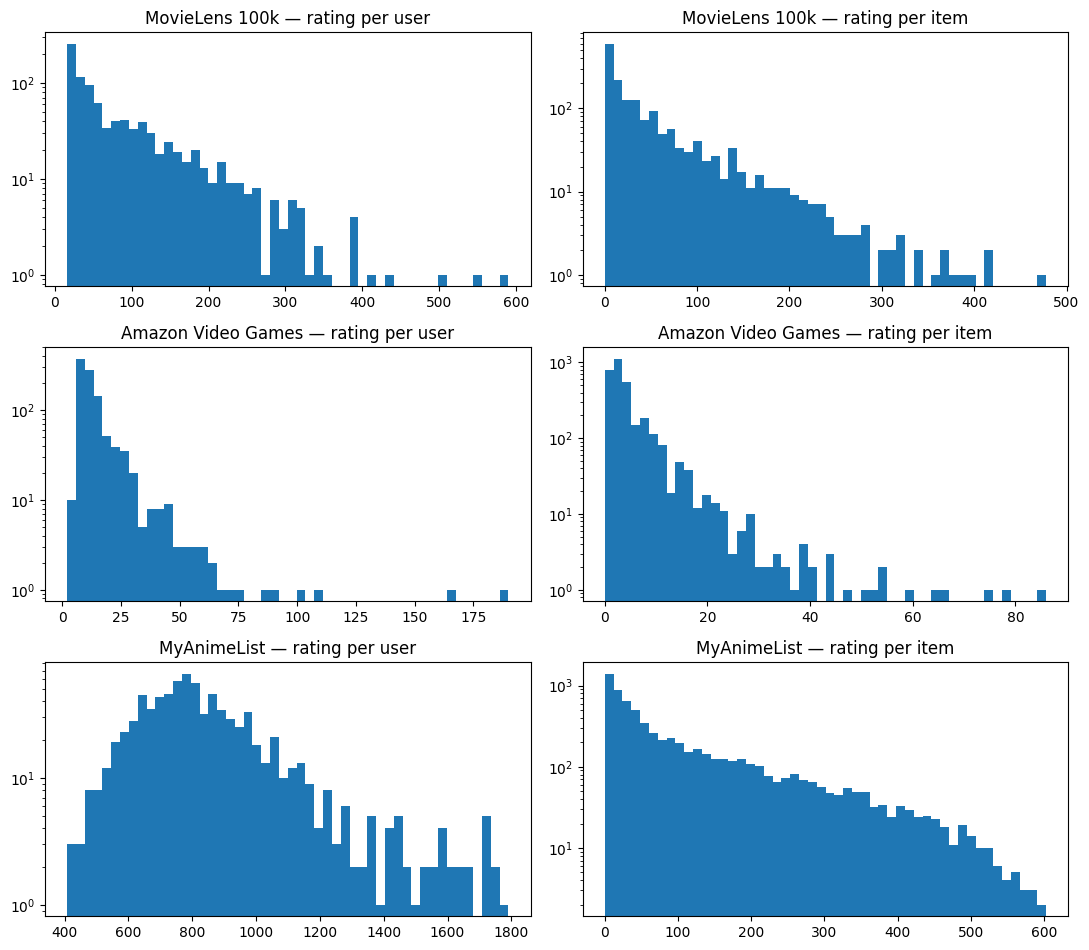

In [6]:
import scipy.sparse as sp

datasets = {
    "MovieLens 100k": sp.coo_matrix(
        (ml_train['rating'], (ml_train['user_idx'], ml_train['item_idx'])),
        shape=(ml_n_users, ml_n_items)
    ).tocsr(),
    "Amazon Video Games": sp.coo_matrix(
        (amz_train['rating'], (amz_train['user_idx'], amz_train['item_idx'])),
        shape=(amz_n_users, amz_n_items)
    ).tocsr(),
    "MyAnimeList": sp.coo_matrix(
        (anime_train['rating'], (anime_train['user_idx'], anime_train['item_idx'])),
        shape=(anime_n_users, anime_n_items)
    ).tocsr()
}

def sparsity(R, name):
    sparsity = 1 - R.nnz / (R.shape[0] * R.shape[1])
    ratings_per_user = np.asarray((R != 0).sum(axis=1)).flatten()
    ratings_per_item = np.asarray((R != 0).sum(axis=0)).flatten()
    print(f"{name}: sparsity = {sparsity:.4%} | "
          f"average rating/user = {ratings_per_user.mean():.1f} | "
          f"average rating/item = {ratings_per_item.mean():.1f}")
    return ratings_per_user, ratings_per_item

fig, axes = plt.subplots(len(datasets), 2, figsize=(11, 3.2*len(datasets)))
for i, (name, R) in enumerate(datasets.items()):
    rpu, rpi = sparsity(R, name)
    axes[i,0].hist(rpu, bins=50); axes[i,0].set_yscale('log')
    axes[i,0].set_title(f"{name} — rating per user")
    axes[i,1].hist(rpi, bins=50); axes[i,1].set_yscale('log')
    axes[i,1].set_title(f"{name} — rating per item")
plt.tight_layout()
plt.show()

## **Grid Search for hyperparameter $\tau$**

In [7]:
def find_best_taus(algo_func, datasets, tau_list, max_iter=100, **kwargs):
    best_parameters = {}

    for name, data in datasets.items():
        t_u, t_i, t_r, n_u, n_i, v_u, v_i, v_r = data
        best_tau = None
        best_val_rmse = float('inf')

        for tau in tau_list:
            _, _, _, _, val_rmse_history, _, _ = algo_func(
                users=t_u, items=t_i, ratings=t_r, n_users=n_u, n_items=n_i,
                tau=tau, max_iter=max_iter,
                v_users=v_u, v_items=v_i, v_ratings=v_r, **kwargs
            )

            final_val_rmse = val_rmse_history[-1]
            if final_val_rmse < best_val_rmse:
                best_val_rmse = final_val_rmse
                best_tau = tau

        best_parameters[name] = best_tau

    return best_parameters

datasets = {
    "Amazon": (amz_t_users, amz_t_items, amz_t_ratings, amz_n_users, amz_n_items, amz_v_users, amz_v_items, amz_v_ratings),
    "MovieLens": (ml_t_users, ml_t_items, ml_t_ratings, ml_n_users, ml_n_items, ml_v_users, ml_v_items, ml_v_ratings),
    "AnimeList": (anime_t_users, anime_t_items, anime_t_ratings, anime_n_users, anime_n_items, anime_v_users, anime_v_items, anime_v_ratings)
}

tau_grid = [4000, 5000, 8000, 10000, 15000, 20000, 22000, 25000, 27000, 30000]

opt_tau_sfw = find_best_taus(frank_wolfe_standard, datasets, tau_grid, tol=1e-4)
opt_tau_pfw = find_best_taus(pairwise_frank_wolfe, datasets, tau_grid, gap_tol=1e-4)
opt_tau_afw = find_best_taus(away_step_frank_wolfe, datasets, tau_grid, gap_tol=1e-4)

print("Optimal Tau for SFW:", opt_tau_sfw)
print("Optimal Tau for PFW:", opt_tau_pfw)
print("Optimal Tau for AFW:", opt_tau_afw)

Initial RMSE: 3.3068
Iter 01/100 | Train Loss: 71398.61 | Gap: 264352.29 | Val RMSE: 3.0375 | Time: 0.01s
Iter 02/100 | Train Loss: 68160.36 | Gap: 307040.23 | Val RMSE: 3.0367 | Time: 0.02s
Iter 03/100 | Train Loss: 55428.21 | Gap: 155468.98 | Val RMSE: 2.7998 | Time: 0.03s
Iter 04/100 | Train Loss: 53445.11 | Gap: 229308.62 | Val RMSE: 2.7772 | Time: 0.04s
Iter 05/100 | Train Loss: 43330.02 | Gap: 109131.26 | Val RMSE: 2.5394 | Time: 0.05s
Iter 06/100 | Train Loss: 42222.75 | Gap: 157128.22 | Val RMSE: 2.5328 | Time: 0.05s
Iter 07/100 | Train Loss: 40608.73 | Gap: 92802.15 | Val RMSE: 2.5051 | Time: 0.06s
Iter 08/100 | Train Loss: 39352.26 | Gap: 77594.59 | Val RMSE: 2.4855 | Time: 0.08s
Iter 09/100 | Train Loss: 39054.28 | Gap: 88198.38 | Val RMSE: 2.4852 | Time: 0.09s
Iter 10/100 | Train Loss: 32935.39 | Gap: 66409.51 | Val RMSE: 2.2938 | Time: 0.10s
Iter 11/100 | Train Loss: 32085.98 | Gap: 150585.70 | Val RMSE: 2.2976 | Time: 0.11s
Iter 12/100 | Train Loss: 31767.08 | Gap: 84031.

In [8]:
# Function to compute RMSE
def compute_rmse(active_set, tau, users, items, ratings):
    """
    The RMSE must be reconstructed from the active rank-1 atoms predictions, avoiding the instantiation of a full dense matrix.

    Parameters:
    - active_set: The final list of atoms returned by the algorithm.
    - tau: The nuclear norm radius.
    - users, items: The test set coordinates arrays.
    - ratings: The test set ratings array.
    """
    preds = np.zeros(len(ratings))

    for atom in active_set:
        if not atom["zero"]:
            # Reconstruct the prediction only for the specific (user, item) pairs in the test set
            preds += atom["alpha"] * tau * (atom["u"][users] * atom["v"][items])


    rmse = np.sqrt(np.mean((preds - ratings) ** 2))

    return rmse

In [9]:
def create_summary_table(results_dict):
    rows = []

    for (dataset, algo), metrics in results_dict.items():
        #percentage gap
        initial_gap = metrics['gap'][0]
        final_gap = metrics['gap'][-1]
        relative_gap_pct = (final_gap / initial_gap) * 100

        # We extract the value from the last iteration
        #train_rmse = metrics['train_rmse'][-1]
        final_val_rmse = metrics['val_rmse'][-1]
        test_rmse = metrics['test_rmse']
        final_size = metrics['size'][-1]
        total_time = metrics['time'][-1]

        # Elements in the table
        rows.append({
            "Dataset": dataset,
            "Algorithm": algo,
            "Relative Gap (%)": f"{relative_gap_pct:.2f}%",
            #"Train RMSE": round(train_rmse, 4),
            "Val RMSE": round(final_val_rmse, 4),
            "Test RMSE": round(test_rmse, 4),
            "Active Rank-1 Atoms": final_size,
            "Total Time (s)": round(total_time, 2)
        })

    df = pd.DataFrame(rows)
    return df

## **Displaying results**

In [10]:
fw_standard_results = {}

print("AMAZON DATASET")
print()
active_amz, _, gap_amz, _, val_amz, size_amz, time_hist_amz = frank_wolfe_standard(
    users=amz_t_users, items=amz_t_items, ratings=amz_t_ratings,
    n_users=amz_n_users, n_items=amz_n_items,
    tau=8500, max_iter=1000, tol=1e-4, gap_tol=1e-3,
    v_users=amz_v_users, v_items=amz_v_items, v_ratings=amz_v_ratings
)
test_amz = compute_rmse(active_amz, 8500, amz_test_users, amz_test_items, amz_test_ratings)

fw_standard_results[("Amazon Video Games", "Frank-Wolfe Standard")] = {
    "tau": 8500,
    "gap": gap_amz,
    "val_rmse": val_amz,
    "test_rmse": test_amz,
    "size": size_amz,
    "time": time_hist_amz
}

print()
print("MOVIELENS DATASET")
active_ml, _, gap_ml, _, val_ml, size_ml, time_hist_ml = frank_wolfe_standard(
    users=ml_t_users, items=ml_t_items, ratings=ml_t_ratings,
    n_users=ml_n_users, n_items=ml_n_items,
    tau=8000, max_iter=500, tol=1e-4, gap_tol=1e-3,
    v_users=ml_v_users, v_items=ml_v_items, v_ratings=ml_v_ratings
)
test_ml = compute_rmse(active_ml, 8000, ml_test_users, ml_test_items, ml_test_ratings)

fw_standard_results[("MovieLens 100k", "Frank-Wolfe Standard")] = {
    "tau": 8000,
    "gap": gap_ml,
    "val_rmse": val_ml,
    "test_rmse": test_ml,
    "size": size_ml,
    "time": time_hist_ml
}

print()
print("MYANIMELIST DATASET")
active_mal, _, gap_mal, _, val_mal, size_mal, time_hist_mal = frank_wolfe_standard(
    users=anime_t_users, items=anime_t_items, ratings=anime_t_ratings,
    n_users=anime_n_users, n_items=anime_n_items,
    tau=22000, max_iter=200, tol=1e-4, gap_tol=1e-3,
    v_users=anime_v_users, v_items=anime_v_items, v_ratings=anime_v_ratings
)
test_mal = compute_rmse(active_mal, 22000, anime_test_users, anime_test_items, anime_test_ratings)

fw_standard_results[("MyAnimeList", "Frank-Wolfe Standard")] = {
    "tau": 22000,
    "gap": gap_mal,
    "val_rmse": val_mal,
    "test_rmse": test_mal,
    "size": size_mal,
    "time": time_hist_ml
}

print()
print("\n Standard Frank-Wolfe Summary")
df_final_summary = create_summary_table(fw_standard_results)
display(df_final_summary)

AMAZON DATASET

Initial RMSE: 3.3068
Iter 01/1000 | Train Loss: 71398.61 | Gap: 561748.62 | Val RMSE: 3.0375 | Time: 0.00s
Iter 02/1000 | Train Loss: 68061.46 | Gap: 652460.49 | Val RMSE: 3.0347 | Time: 0.01s
Iter 03/1000 | Train Loss: 54914.49 | Gap: 339366.30 | Val RMSE: 2.7911 | Time: 0.01s
Iter 04/1000 | Train Loss: 52719.84 | Gap: 503055.62 | Val RMSE: 2.7640 | Time: 0.02s
Iter 05/1000 | Train Loss: 49018.56 | Gap: 241750.57 | Val RMSE: 2.6981 | Time: 0.02s
Iter 06/1000 | Train Loss: 48135.83 | Gap: 337494.99 | Val RMSE: 2.6996 | Time: 0.02s
Iter 07/1000 | Train Loss: 40681.42 | Gap: 212484.08 | Val RMSE: 2.4940 | Time: 0.03s
Iter 08/1000 | Train Loss: 38901.02 | Gap: 485024.55 | Val RMSE: 2.4911 | Time: 0.03s
Iter 09/1000 | Train Loss: 38127.71 | Gap: 204524.38 | Val RMSE: 2.4908 | Time: 0.03s
Iter 10/1000 | Train Loss: 34752.90 | Gap: 160882.20 | Val RMSE: 2.3799 | Time: 0.04s
Iter 11/1000 | Train Loss: 33740.16 | Gap: 348699.27 | Val RMSE: 2.3796 | Time: 0.04s
Iter 12/1000 | Tr

,Dataset,Algorithm,Relative Gap (%),Val RMSE,Test RMSE,Active Rank-1 Atoms,Total Time (s)
0,Amazon Video Games,Frank-Wolfe Standard,0.04%,1.4751,1.4646,750,9.90
1,MovieLens 100k,Frank-Wolfe Standard,0.25%,1.0277,1.0017,501,8.68
2,MyAnimeList,Frank-Wolfe Standard,0.09%,0.2040,0.2062,201,8.68


In [11]:
away_step_results = {}

# 1) AMAZON VIDEO
print("AMAZON VIDEO GAMES DATASET")
print()
active_amz_as, _, gap_amz_as, _, val_amz_as, size_amz_as, time_hist_amz_as = away_step_frank_wolfe(
    users=amz_t_users, items=amz_t_items, ratings=amz_t_ratings,
    n_users=amz_n_users, n_items=amz_n_items,
    tau=8500, max_iter=1000, gap_tol=1e-3,
    v_users=amz_v_users, v_items=amz_v_items, v_ratings=amz_v_ratings
)
test_amz_as = compute_rmse(active_amz_as, 8500, amz_test_users, amz_test_items, amz_test_ratings)

away_step_results[("Amazon Video Games", "Away Step Frank_Wolfe")] = {
    "tau": 8500,
    "gap": gap_amz_as,
    "val_rmse": val_amz_as,
    "test_rmse": test_amz_as,
    "size": size_amz_as,
    "time": time_hist_amz_as
    }

# 2) MOVIELENS 100K MYANIMELIST
print("\n MOVIELENS 100K")
active_ml_as, _, gap_ml_as, _, val_ml_as, size_ml_as, time_hist_ml_as = away_step_frank_wolfe(
    users=ml_t_users, items=ml_t_items, ratings=ml_t_ratings,
    n_users=ml_n_users, n_items=ml_n_items,
    tau=8000, max_iter=500, gap_tol=1e-3,
    v_users=ml_v_users, v_items=ml_v_items, v_ratings=ml_v_ratings
)
test_ml_as = compute_rmse(active_ml_as, 8000, ml_test_users, ml_test_items, ml_test_ratings)

away_step_results[("MovieLens 100k", "Away Step Frank_Wolfe")] = {
    "tau": 8000,
    "gap": gap_ml_as,
    "val_rmse": val_ml_as,
    "test_rmse": test_ml_as,
    "size": size_ml_as,
    "time": time_hist_ml_as
}

# MYANIMELIST
print("\n MYANIMELIST DATASET")
active_mal_as, _, gap_mal_as, _, val_mal_as, size_mal_as, time_hist_mal_as = away_step_frank_wolfe(
    users=anime_t_users, items=anime_t_items, ratings=anime_t_ratings,
    n_users=anime_n_users, n_items=anime_n_items,
    tau=22000, max_iter=200, gap_tol=1e-3,
    v_users=anime_v_users, v_items=anime_v_items, v_ratings=anime_v_ratings
)
test_mal_as = compute_rmse(active_mal_as, 22000, anime_test_users, anime_test_items, anime_test_ratings)

away_step_results[("MyAnimeList", "Away Step Frank_Wolfe")] = {
    "tau": 22000,
    "gap": gap_mal_as,
    "val_rmse": val_mal_as,
    "test_rmse": test_mal_as,
    "size": size_mal_as,
    "time": time_hist_mal_as
}

print("\n Away-Step Frank-Wolfe Summary")
df_final_summary = create_summary_table(away_step_results)
display(df_final_summary)

AMAZON VIDEO GAMES DATASET

Iter 01/1000 | Train Loss: 85166.00 | Gap: 561748.62 | Val RMSE: 3.3068 | Time: 0.00s | Step: FW
Iter 02/1000 | Train Loss: 71398.61 | Gap: 652460.49 | Val RMSE: 3.0375 | Time: 0.01s | Step: FW
Iter 03/1000 | Train Loss: 68061.46 | Gap: 339366.30 | Val RMSE: 3.0347 | Time: 0.01s | Step: FW
Iter 04/1000 | Train Loss: 54914.49 | Gap: 503055.62 | Val RMSE: 2.7911 | Time: 0.02s | Step: FW
Iter 05/1000 | Train Loss: 52719.84 | Gap: 241750.57 | Val RMSE: 2.7640 | Time: 0.02s | Step: FW
Iter 06/1000 | Train Loss: 49018.56 | Gap: 337494.99 | Val RMSE: 2.6981 | Time: 0.02s | Step: FW
Iter 07/1000 | Train Loss: 48135.83 | Gap: 212484.08 | Val RMSE: 2.6996 | Time: 0.03s | Step: FW
Iter 08/1000 | Train Loss: 40681.42 | Gap: 485024.55 | Val RMSE: 2.4940 | Time: 0.03s | Step: FW
Iter 09/1000 | Train Loss: 38901.02 | Gap: 204524.38 | Val RMSE: 2.4911 | Time: 0.04s | Step: FW
Iter 10/1000 | Train Loss: 38127.71 | Gap: 160882.20 | Val RMSE: 2.4908 | Time: 0.04s | Step: FW
It

,Dataset,Algorithm,Relative Gap (%),Val RMSE,Test RMSE,Active Rank-1 Atoms,Total Time (s)
0,Amazon Video Games,Away Step Frank_Wolfe,0.24%,1.5116,1.5093,467,17.14
1,MovieLens 100k,Away Step Frank_Wolfe,0.27%,1.0263,1.0062,459,27.39
2,MyAnimeList,Away Step Frank_Wolfe,0.10%,0.2589,0.2608,154,73.97


In [12]:
pairwise_results = {}

# 1) AMAZON VIDEO
print("AMAZON VIDEO GAMES DATASET")
active_amz_pair, _, gap_amz_pair, _, val_amz_pair, size_amz_pair, time_hist_amz_pair = pairwise_frank_wolfe(
    users=amz_t_users, items=amz_t_items, ratings=amz_t_ratings,
    n_users=amz_n_users, n_items=amz_n_items,
    tau=8500, max_iter=1000, gap_tol=1e-3,
    v_users=amz_v_users, v_items=amz_v_items, v_ratings=amz_v_ratings
)
test_amz_pair = compute_rmse(active_amz_pair, 8500, amz_test_users, amz_test_items, amz_test_ratings)

pairwise_results[("Amazon Video Games", "Pairwise Frank-Wolfe")] = {
    "tau": 8500,
    "gap": gap_amz_pair,
    "val_rmse": val_amz_pair,
    "test_rmse": test_amz_pair,
    "size": size_amz_pair,
    "time": time_hist_amz_pair
    }

# 2) MOVIELENS 100K
print("\n MOVIELENS DATASET")


active_ml_pair, _, gap_ml_pair, _, val_ml_pair, size_ml_pair, time_hist_ml_pair = pairwise_frank_wolfe(
    users=ml_t_users, items=ml_t_items, ratings=ml_t_ratings,
    n_users=ml_n_users, n_items=ml_n_items,
    tau=8000, max_iter=500, gap_tol=1e-3,
    v_users=ml_v_users, v_items=ml_v_items, v_ratings=ml_v_ratings
)
test_ml_pair = compute_rmse(active_ml_pair, 8000, ml_test_users, ml_test_items, ml_test_ratings)

pairwise_results[("MovieLens 100k", "Pairwise Frank-Wolfe")] = {
    "tau": 8000,
    "gap": gap_ml_pair,
    "val_rmse": val_ml_pair,
    "test_rmse": test_ml_pair,
    "size": size_ml_pair,
    "time": time_hist_ml_pair
}

# 2) MYANIMELIST
print("\n MYANIMELIST DATASET")


active_mal_pair, _, gap_mal_pair, _, val_mal_pair, size_mal_pair, time_hist_mal_pair = pairwise_frank_wolfe(
    users=anime_t_users, items=anime_t_items, ratings=anime_t_ratings,
    n_users=anime_n_users, n_items=anime_n_items,
    tau=22000, max_iter=200, gap_tol=1e-3,
    v_users=anime_v_users, v_items=anime_v_items, v_ratings=anime_v_ratings
)
test_mal_pair = compute_rmse(active_mal_pair, 22000, anime_test_users, anime_test_items, anime_test_ratings)

pairwise_results[("MyAnimeList", "Pairwise Frank-Wolfe")] = {
    "tau": 22000,
    "gap": gap_mal_pair,
    "val_rmse": val_mal_pair,
    "test_rmse": test_mal_pair,
    "size": size_mal_pair,
    "time": time_hist_mal_pair
}

print("\n*** Pair-Wise Frank-Wolfe Summary ***")
df_final_summary = create_summary_table(pairwise_results)
display(df_final_summary)

AMAZON VIDEO GAMES DATASET
Iter 01/1000 | Train Loss: 85166.00 | Gap: 561748.62 | Val RMSE: 3.3068 | Time: 0.00s
Iter 02/1000 | Train Loss: 71398.61 | Gap: 652460.49 | Val RMSE: 3.0375 | Time: 0.01s
Iter 03/1000 | Train Loss: 69411.92 | Gap: 350224.86 | Val RMSE: 3.0573 | Time: 0.01s
Iter 04/1000 | Train Loss: 55657.91 | Gap: 525373.12 | Val RMSE: 2.7985 | Time: 0.02s
Iter 05/1000 | Train Loss: 53229.93 | Gap: 254035.89 | Val RMSE: 2.7680 | Time: 0.02s
Iter 06/1000 | Train Loss: 52723.75 | Gap: 240917.26 | Val RMSE: 2.7717 | Time: 0.02s
Iter 07/1000 | Train Loss: 46390.42 | Gap: 369417.25 | Val RMSE: 2.6163 | Time: 0.03s
Iter 08/1000 | Train Loss: 45241.82 | Gap: 198369.75 | Val RMSE: 2.6098 | Time: 0.03s
Iter 09/1000 | Train Loss: 42664.26 | Gap: 246252.72 | Val RMSE: 2.5498 | Time: 0.03s
Iter 10/1000 | Train Loss: 42062.49 | Gap: 180498.93 | Val RMSE: 2.5495 | Time: 0.04s
Iter 11/1000 | Train Loss: 32837.13 | Gap: 381374.73 | Val RMSE: 2.3093 | Time: 0.04s
Iter 12/1000 | Train Loss: 

,Dataset,Algorithm,Relative Gap (%),Val RMSE,Test RMSE,Active Rank-1 Atoms,Total Time (s)
0,Amazon Video Games,Pairwise Frank-Wolfe,0.78%,1.8539,1.8417,878,27.93
1,MovieLens 100k,Pairwise Frank-Wolfe,0.36%,1.1316,1.1215,483,28.20
2,MyAnimeList,Pairwise Frank-Wolfe,0.21%,0.2887,0.2972,194,94.70


## **Relevant Plots**

**Active Set Size vs. Iterations (The Mechanics of Drop Steps)**

* **Metric Monitored:** The vertical axis tracks the cardinality of the active set—the exact number of historical rank-1 atoms that maintain a strictly positive weight ($\alpha > 0$) in the convex combination at any given iteration $k$.
* **Algorithmic Behavior:** It explicitly visualizes the internal pruning mechanics of the optimization algorithms. Standard FW is mathematically forced to grow linearly (adding up to one atom per step). By plotting all three side-by-side, we observe whether Pairwise and Away-Step FW are successfully triggering their defining feature: "drop steps" that prune suboptimal atoms from the expansion.
* **Computational Footprint:** The size of the active set directly dictates the per-iteration computational complexity. Tracking this growth exposes the hidden overhead of the advanced variants, as they must evaluate the gradient against every single active atom to locate the "worst" atom $v_k$.
* **Domain Geometry Check:** Ultimately, plotting this metric serves as a structural diagnostic tool. It tests how the continuous, curved geometry of the nuclear norm ball interacts with the theoretical sparsity guarantees of the Away-Step and Pairwise heuristics compared to their behavior on standard polytopes.

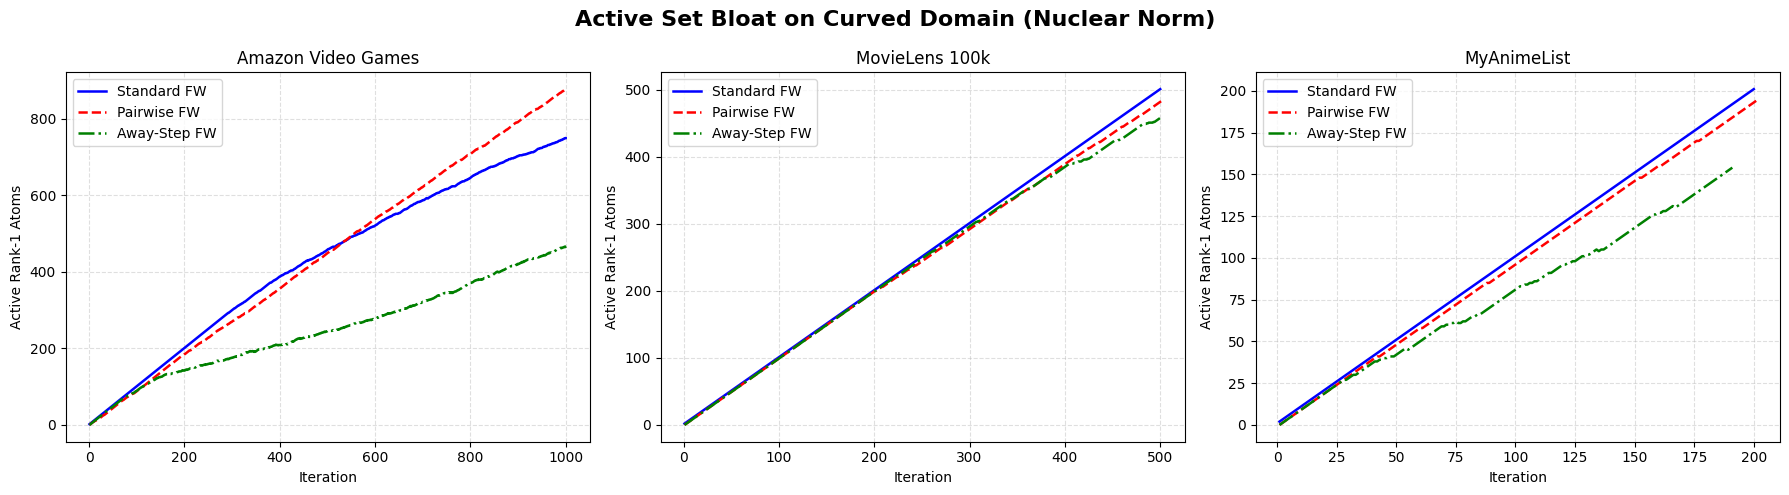

In [13]:
def plot_all_active_sets(results_sfw, results_pfw, results_afw):
    datasets = ["Amazon Video Games", "MovieLens 100k", "MyAnimeList"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    fig.suptitle("Active Set Bloat on Curved Domain (Nuclear Norm)", fontsize=16, fontweight='bold')
    
    for ax, dataset in zip(axes, datasets):
        # Extract data using the exact dictionary keys from your code
        size_sfw = results_sfw[(dataset, "Frank-Wolfe Standard")]['size']
        size_pfw = results_pfw[(dataset, "Pairwise Frank-Wolfe")]['size']
        size_afw = results_afw[(dataset, "Away Step Frank_Wolfe")]['size']
        
        # Plot each algorithm
        ax.plot(range(1, len(size_sfw) + 1), size_sfw, label='Standard FW', color='blue', linewidth=1.8)
        ax.plot(range(1, len(size_pfw) + 1), size_pfw, label='Pairwise FW', color='red', linewidth=1.8, linestyle='--')
        ax.plot(range(1, len(size_afw) + 1), size_afw, label='Away-Step FW', color='green', linewidth=1.8, linestyle='-.')
        
        # Formatting
        ax.set_title(dataset)
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Active Rank-1 Atoms")
        ax.legend()
        ax.grid(True, which="both", ls="--", alpha=0.4)
        
    plt.tight_layout()
    plt.show()

# Execution call for your notebook
plot_all_active_sets(fw_standard_results, pairwise_results, away_step_results)

**Convergence Analysis (Duality Gap vs. Iterations & Time)**

* **Metric Monitored:** The vertical axis tracks the Relative Duality Gap ($g_t / g_0$) on a logarithmic scale. The duality gap provides a strict mathematical upper bound on how far the current solution is from the true global optimum. Normalizing it by the initial gap ($g_0$) ensures a consistent, percentage-based scaling across different datasets.
* **Left Plot (Gap vs. Iterations):** This evaluates *theoretical algorithmic efficiency*. It measures how much optimization progress is made with every mathematical step, independent of how long that step took to compute. It verifies that all variants successfully minimize the objective function and follow the expected sublinear convergence trajectory.
* **Right Plot (Gap vs. Time):** This evaluates *practical computational efficiency*. It translates mathematical steps into real-world wall-clock seconds, effectively exposing the hidden computational overhead of each algorithm. 
* **The Side-by-Side Contrast:** Presenting these two views together reveals the core tradeoff of the project. It shows that even if an advanced heuristic (like Pairwise or Away-Step) performs well per iteration, the heavy computational cost of managing a bloated active set destroys its real-world speed, allowing the mathematically simpler Standard FW to reach convergence drastically faster.

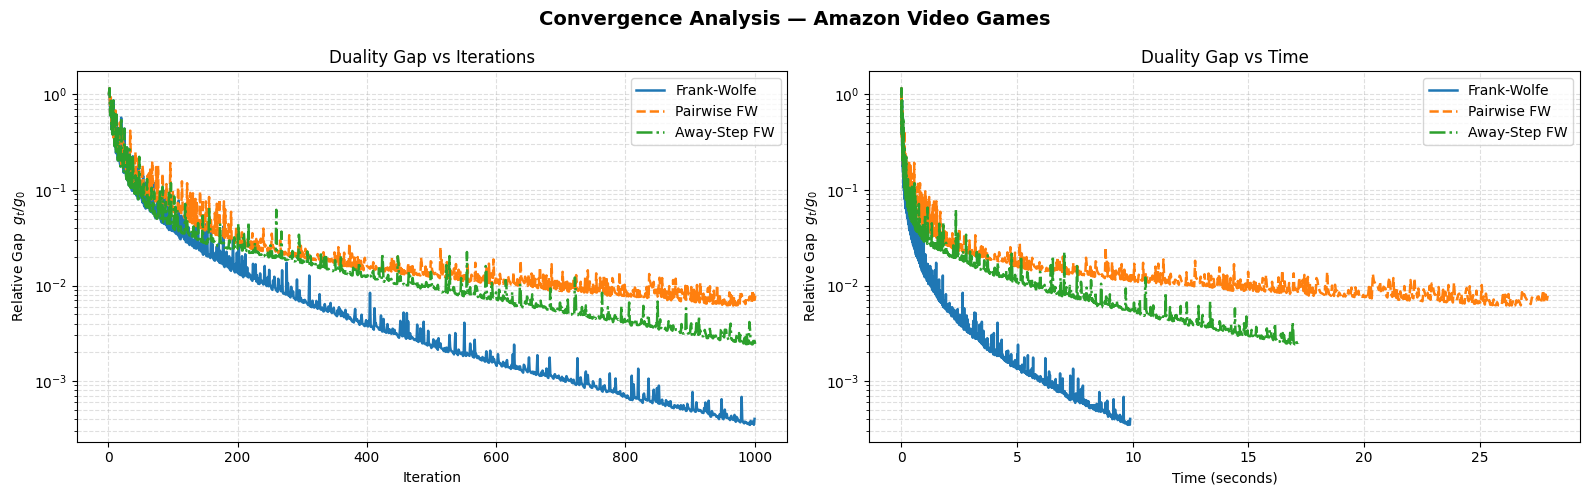

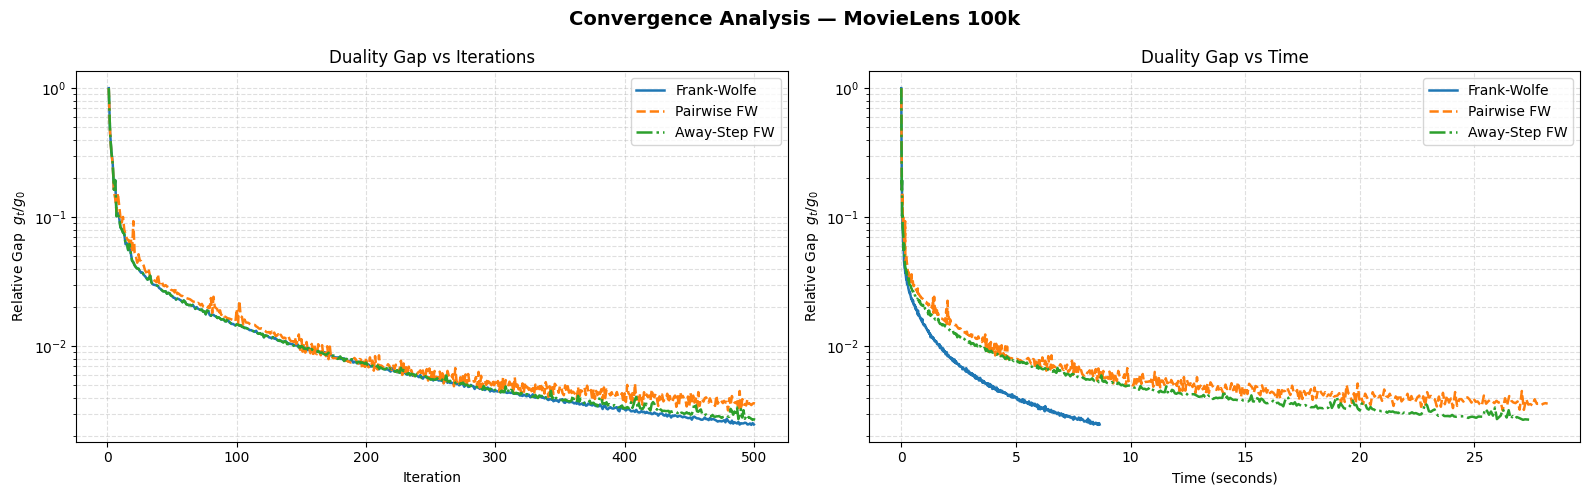

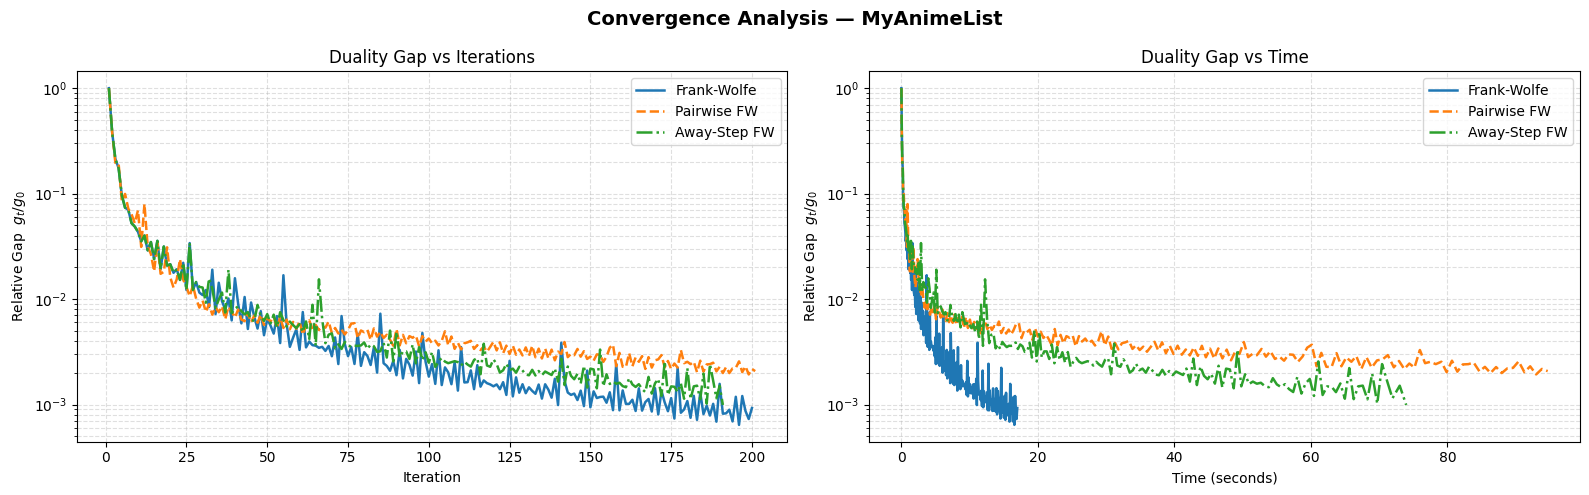

In [14]:
def plot_convergence_side_by_side(gap_fw, gap_pfw, gap_afw, time_fw, time_pfw, time_afw, dataset_name):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(f"Convergence Analysis — {dataset_name}", fontsize=14, fontweight='bold')

    # --- Plot 1: Duality Gap vs Iterations ---
    ax1 = axes[0]
    for gap_hist, label, style in [
        (gap_fw, "Frank-Wolfe", "-"),
        (gap_pfw, "Pairwise FW", "--"),
        (gap_afw, "Away-Step FW", "-."),
    ]:
        gap_arr = np.array(gap_hist)
        gap_arr = np.maximum(gap_arr, 1e-12)  # to prevent log(0)
        rel_gap = gap_arr / gap_arr[0]
        ax1.plot(range(1, len(rel_gap) + 1), rel_gap, style, label=label, linewidth=1.8)

    ax1.set_yscale("log")
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel(r"Relative Gap  $g_t / g_0$")
    ax1.set_title("Duality Gap vs Iterations")
    ax1.legend()
    ax1.grid(True, which="both", ls="--", alpha=0.4)

    # --- Plot 2: Duality Gap vs Time ---
    ax2 = axes[1]
    for gap_hist, time_hist, label, style in [
        (gap_fw, time_fw, "Frank-Wolfe", "-"),
        (gap_pfw, time_pfw, "Pairwise FW", "--"),
        (gap_afw, time_afw, "Away-Step FW", "-."),
    ]:
        gap_arr = np.array(gap_hist)
        gap_arr = np.maximum(gap_arr, 1e-12)
        rel_gap = gap_arr / gap_arr[0]

        n = min(len(rel_gap), len(time_hist) + 1)
        x = [0.0] + list(time_hist[: n - 1])
        y = rel_gap[:n]

        ax2.plot(x, y, style, label=label, linewidth=1.8)

    ax2.set_yscale("log")
    ax2.set_xlabel("Time (seconds)")
    ax2.set_ylabel(r"Relative Gap  $g_t / g_0$")
    ax2.set_title("Duality Gap vs Time")
    ax2.legend()
    ax2.grid(True, which="both", ls="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

# Execution 
plot_convergence_side_by_side(
    gap_amz, gap_amz_pair, gap_amz_as, 
    time_hist_amz, time_hist_amz_pair, time_hist_amz_as, 
    "Amazon Video Games"
)

plot_convergence_side_by_side(
    gap_ml, gap_ml_pair, gap_ml_as, 
    time_hist_ml, time_hist_ml_pair, time_hist_ml_as, 
    "MovieLens 100k"
)

plot_convergence_side_by_side(
    gap_mal, gap_mal_pair, gap_mal_as, 
    time_hist_mal, time_hist_mal_pair, time_hist_mal_as, 
    "MyAnimeList"
)

**Out-of-Sample Performance (Test RMSE)**

* **Metric Monitored:** The vertical axis displays the Root Mean Squared Error (RMSE) evaluated exclusively on the completely unseen hold-out Test Set. Lower values indicate better predictive accuracy.
* **Generalization vs. Optimization:** While the duality gap and active set plots analyze the internal mathematical mechanics of the optimization process, this chart evaluates the final utility of the models from a pure Machine Learning perspective. It measures how well the generated low-rank matrices generalize to predict new user-item preferences.
* **Final Model Quality:** By comparing the test scores side-by-side, this visualization serves as the definitive conclusion of the experiment. It demonstrates that the severe active set bloat and sub-optimal direction choices of the Pairwise and Away-Step variants on a curved domain do not just slow them down—they ultimately result in inferior out-of-sample predictions. Standard Frank-Wolfe remains the most robust and accurate choice.

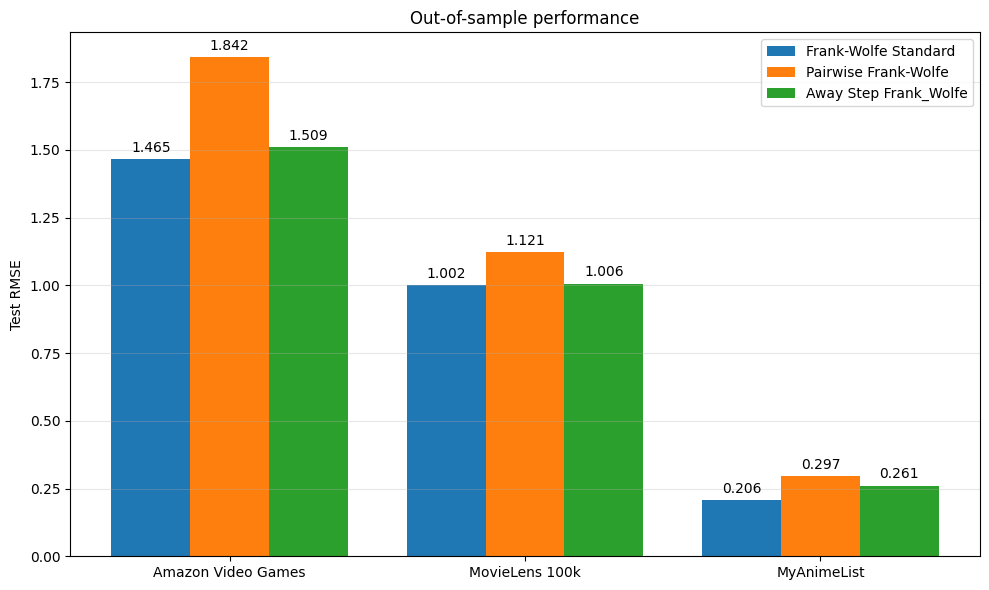

In [15]:
def plot_test_rmse(comparative_results):
    rows = []
    for (dataset, algorithm), metrics in comparative_results.items():
        rows.append({
            "Dataset": dataset,
            "Algorithm": algorithm,
            "Test RMSE": metrics["test_rmse"]
        })

    df = pd.DataFrame(rows)

    datasets = df["Dataset"].unique()
    algorithms = df["Algorithm"].unique()

    x = np.arange(len(datasets))
    width = 0.8 / len(algorithms)

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, algorithm in enumerate(algorithms):
        values = []
        for dataset in datasets:
            row = df[
                (df["Dataset"] == dataset)
                & (df["Algorithm"] == algorithm)
            ]
            if len(row) > 0:
                values.append(row["Test RMSE"].iloc[0])
            else:
                values.append(np.nan)

        offset = (i - (len(algorithms) - 1) / 2) * width
        bars = ax.bar(
            x + offset,
            values,
            width,
            label=algorithm
        )

        ax.bar_label(
            bars,
            fmt="%.3f",
            padding=3
        )

    ax.set_xticks(x)
    ax.set_xticklabels(datasets)
    ax.set_ylabel("Test RMSE")
    ax.set_title("Out-of-sample performance")
    ax.legend()

    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

final_test_results = {}
final_test_results.update(fw_standard_results)
final_test_results.update(pairwise_results)
final_test_results.update(away_step_results)

plot_test_rmse(final_test_results)